## Train an XGBoost model by manually implementing gradient boosting with weak learners, compare its accuracy with Random Forest, and analyze feature importance differences between both models.

In [1]:
import pandas as pd
import random
import math

In [2]:
df = pd.read_csv("heart.csv")

X = df.drop("target", axis=1).values.tolist()
y = df["target"].tolist()

print("Dataset loaded:", len(X))

Dataset loaded: 303


In [3]:
random.seed(42)

data = list(zip(X, y))
random.shuffle(data)

split = int(len(data) * 0.8)

train = data[:split]
test = data[split:]

X_train = [r[0] for r in train]
y_train = [r[1] for r in train]
X_test = [r[0] for r in test]
y_test = [r[1] for r in test]

In [4]:

def make_stump(X, residuals):
    best_error = float("inf")
    best_stump = None

    for feature in range(len(X[0])):
        values = sorted(set(row[feature] for row in X))

        for i in range(len(values) - 1):
            threshold = (values[i] + values[i + 1]) / 2

            left = [j for j in range(len(X))
                    if X[j][feature] <= threshold]
            right = [j for j in range(len(X))
                     if X[j][feature] > threshold]

            if not left or not right:
                continue

            left_value = sum(residuals[j] for j in left) / len(left)
            right_value = sum(residuals[j] for j in right) / len(right)

            error = sum((residuals[j] - left_value) ** 2 for j in left)
            error += sum((residuals[j] - right_value) ** 2 for j in right)

            if error < best_error:
                best_error = error
                best_stump = (feature, threshold, left_value, right_value)

    return best_stump


In [5]:

def train_boosting(X, y, rounds=10, rate=0.1):
    scores = [0.0] * len(y)
    stumps = []

    for _ in range(rounds):
        probabilities = [1 / (1 + math.exp(-s)) for s in scores]
        residuals = [actual - prob for actual, prob in zip(y, probabilities)]

        stump = make_stump(X, residuals)

        if stump is None:
            break

        feature, threshold, left, right = stump

        for i, row in enumerate(X):
            if row[feature] <= threshold:
                scores[i] += rate * left
            else:
                scores[i] += rate * right

        stumps.append(stump)

    return stumps


boost_model = train_boosting(X_train, y_train)

print("Boosting training completed!")
print("Weak learners:", len(boost_model))


Boosting training completed!
Weak learners: 10


In [6]:

def predict_boost(model, row):
    score = 0

    for feature, threshold, left, right in model:
        if row[feature] <= threshold:
            score += 0.1 * left
        else:
            score += 0.1 * right

    return 1 if score >= 0 else 0


predictions = [predict_boost(boost_model, row) for row in X_test]

correct = sum(a == p for a, p in zip(y_test, predictions))
boost_accuracy = correct / len(y_test) * 100

print("Boosting Accuracy:", round(boost_accuracy, 2), "%")


Boosting Accuracy: 73.77 %


In [8]:

rf_accuracy = float(input("Enter Task 1 Random Forest accuracy: "))

print("Random Forest Accuracy:", rf_accuracy, "%")
print("Boosting Accuracy:", round(boost_accuracy, 2), "%")

if boost_accuracy > rf_accuracy:
    print("Boosting performed better.")
elif boost_accuracy < rf_accuracy:
    print("Random Forest performed better.")
else:
    print("Both models have equal accuracy.")


Enter Task 1 Random Forest accuracy:  78.69


Random Forest Accuracy: 78.69 %
Boosting Accuracy: 73.77 %
Random Forest performed better.


In [11]:

# Feature importance comparison

boost_features = [0] * len(X_train[0])

for stump in boost_model:
    boost_features[stump[0]] += 1

importance = pd.DataFrame({
    "Feature": df.drop("target", axis=1).columns,
    "Boosting": boost_features
})

print("Boosting Feature Importance:")
print(importance.sort_values("Boosting", ascending=False))


Boosting Feature Importance:
     Feature  Boosting
2         cp         5
12      thal         3
11        ca         2
0        age         0
1        sex         0
3   trestbps         0
4       chol         0
5        fbs         0
6    restecg         0
7    thalach         0
8      exang         0
9    oldpeak         0
10     slope         0


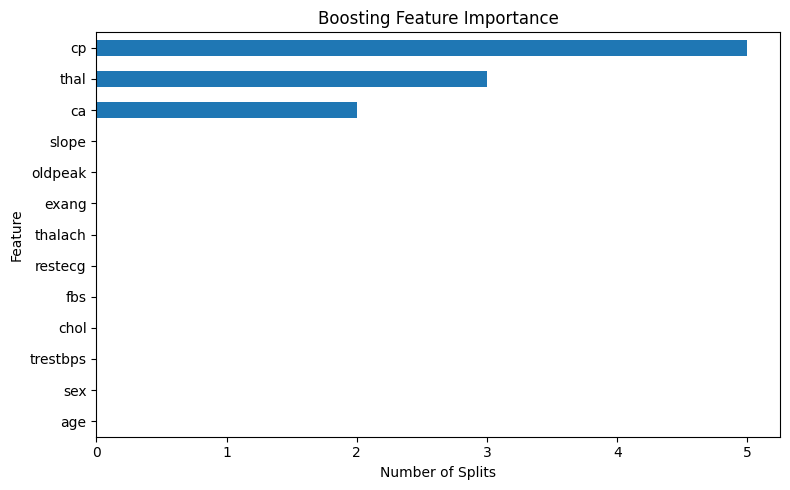

In [12]:

import matplotlib.pyplot as plt

importance.sort_values("Boosting").plot(
    x="Feature",
    y="Boosting",
    kind="barh",
    figsize=(8, 5),
    legend=False
)

plt.title("Boosting Feature Importance")
plt.xlabel("Number of Splits")
plt.tight_layout()
plt.show()
